In [51]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [52]:
def f_normal(x):
  return 2*np.exp(-(x**2)/2)/np.sqrt(2*np.pi)

def g_normal(x):
  return np.exp(-x)

def normal(mi, sigma, M):
  c = 2*np.exp(1/2)/np.sqrt(2*np.pi)

  amostra = []
  while len(amostra) < M:
    u = np.random.uniform()
    y = (-1) * np.log(np.random.uniform())

    if(u < f_normal(y)/(c*g_normal(y))):
      amostra.append(y)

  for i in range(len(amostra)):
    if(np.random.uniform() < 0.5):
      amostra[i] = -amostra[i]

  if(mi != 0 or sigma != 1):
    for i in range(len(amostra)):
      amostra[i] = (amostra[i] * sigma) + mi

  return amostra

def f_plot_normal(x, mi):
  return np.exp(-((x-mi)**2)/2)/np.sqrt(2*np.pi)

def plot_normal(minimo, maximo, mi):
    valor = []
    for x in np.linspace(minimo, maximo, 10_000):
      valor.append(f_plot_normal(x, mi))

    return [np.linspace(minimo, maximo, 10_000), valor]


def f_exponencial(x, lam):
    return lam * np.exp(-lam * x)

def exp(lam):
    valor = []
    for x in np.linspace(0, 8, 10_000):
      valor.append(f_exponencial(x, lam))

    return valor

def exponencial(lam, M):
  amostra = []
  for i in range(M):
    x = (-1/lam) * np.log(np.random.uniform())
    amostra.append(x)
  
  return amostra


def f_gama(x, alpha, beta):
  return (beta**alpha)/(math.gamma(alpha)) * x**(alpha-1) * np.exp(-beta * x)


# Exercício 1

Para cada distribuição abaixo, plote no mesmo gráfico a densidade (ou massa) original $f$ e as versões inclinadas $f_t$ para alguns valores de $t$, positivos e negativos.

1. $N(0, 1)$, com $t \in \{-2, -1, 0, 1, 2\}$
2. $\text{Exp}(1)$, com $t \in \{-1, -0.5, 0, 0.5, 0.75\}$
3. $\text{Gamma}(3, 2)$, com $t \in \{-2, -1, 0, 0.5, 1\}$
4. $\text{Poisson}(4)$, com $t \in \{-1, -0.5, 0, 0.5, 1\}$
5. $\text{Bin}(20, 0.3)$, com $t \in \{-1, -0.5, 0, 0.5, 1\}$

Para cada caso, descreva o efeito do tilt: o que acontece com a média e com a cauda quando $t > 0$ e quando $t < 0$?


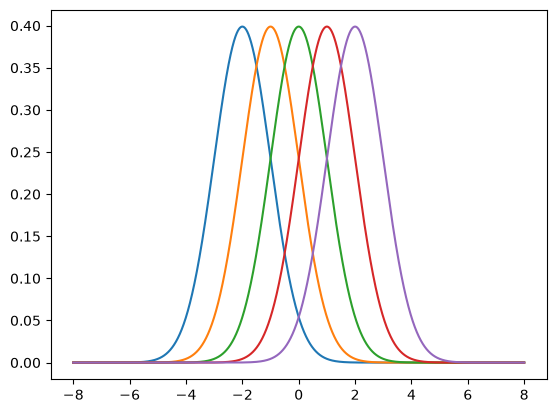

In [53]:
t = [-2 , -1, 0, 1, 2]
for x in t:
    values = plot_normal(-8, 8, x)
    plt.plot(values[0], values[1])
plt.show()


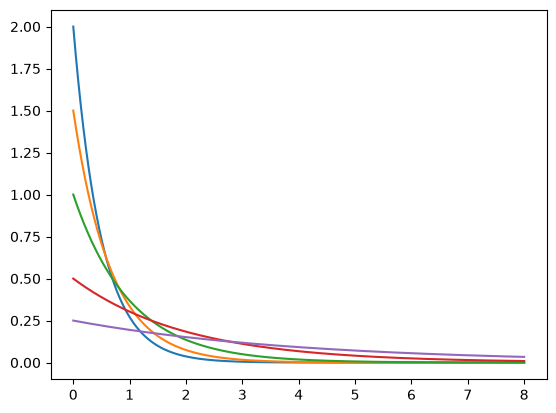

In [54]:
t = [-1, -0.5, 0, 0.5, 0.75]

for i in t:
    plt.plot(np.linspace(0, 8, 10_000), exp(1-i))

plt.show()
    

In [55]:
t = [-2, -1, 0, 0.5, 1]

# Exercício 2

Seja $X \sim N(0,1)$. Queremos estimar

$$
\theta = P(X > 5) \approx 2.87 \times 10^{-7}.
$$

1. **Monte Carlo ingênuo.** Estime $\theta$ amostrando $N = 200{,}000$ valores de $N(0,1)$. Quantas amostras caíram no evento $\{X > 5\}$? A estimativa é confiável?

2. **Escolha da proposta.** Usando o Exercício 1, pense em uma densidade inclinada $f_t$ de $N(0,1)$ que coloque massa na região que importa. Qual valor de $t$ parece razoável? Justifique.

3. **Amostragem por importância.** Amostre de $f_t$ e estime $\theta$ com os pesos $f(x)/f_t(x)$. Compare com o valor exato e com o resultado do item 1.

4. **Sensibilidade a $t$.** Repita o item 3 para alguns valores de $t$, por exemplo $t \in \{1, 3, 5, 7\}$. Compare o erro relativo das estimativas. Qual $t$ funciona melhor, e por quê?


In [56]:
dados = normal(0, 1, 200_000)

p_chapeu = np.mean(np.array(dados) > 5)

print(p_chapeu)

0.0


2. $t = 5$

In [ ]:
t = 5

f_t = normal(t, 1, 200_000)

soma = []
for x in f_t:
    if(x > 5):
        soma.append(np.exp(-t * x + (t**2)/2))

    else:
        soma.append(0)

print(np.mean(soma))

2.8715921680794386e-07


In [61]:
t = [1, 3, 5, 7]

for i in t:
    f_t = normal(i, 1, 200_000)
    soma = []
    for x in f_t:
        if(x > 5):
            soma.append(np.exp(-i * x + (i**2)/2))

        else:
            soma.append(0)

    print(f"para t = {i} o valor obtido foi: {np.mean(soma)}")

para t = 1 o valor obtido foi: 1.3954643468012022e-07
para t = 3 o valor obtido foi: 2.908894369911363e-07
para t = 5 o valor obtido foi: 2.874469347778083e-07
para t = 7 o valor obtido foi: 2.822254683511612e-07


# Exercício 3

Seja $X \sim \text{Exp}(1)$. Queremos estimar

$$
\theta = P(X > 20) = e^{-20} \approx 2.06 \times 10^{-9}.
$$

1. **Monte Carlo ingênuo.** Estime $\theta$ com $N = 200{,}000$ amostras de $\text{Exp}(1)$. O que acontece?

2. **Escolha da proposta.** A densidade inclinada de $\text{Exp}(1)$ é $\text{Exp}(1-t)$, com $t < 1$.
   - Para colocar massa perto de $x = 20$, a cauda da proposta deve ficar mais leve ou mais pesada?
   - Qual é o sinal de $t$?
   - Proponha um valor de $t$ de modo que a média da proposta fique em $20$.

3. **Amostragem por importância.** Amostre de $\text{Exp}(1-t)$ e estime $\theta$ com os pesos $f(x)/f_t(x)$. Compare com o valor exato e com o item 1.

4. **Sensibilidade a $t$.** Repita o item 3 para $t \in \{0.5,\ 0.9,\ 0.95,\ 0.99\}$. Compare o erro relativo das estimativas. O que acontece quando $t \to 1$?


In [ ]:
dados = exponencial(1, 200_000)

p_chapeu = np.mean(np.array(dados) > 20)

print(p_chapeu)

0.0


2. 

A cauda deve ficar mais pesada. 

t é positivo 

$t = 19/20$


In [ ]:
t = 19/20

f_t = exponencial(1-t, 200_000)

soma = []
for x in f_t:
    if(x > 20):
        soma.append(np.exp(-t * x) * 1/(1-t))

    else:
        soma.append(0)

print(np.mean(soma))

2.0721971436617354e-09


In [ ]:
t = [0.5 , 0.9, 0.95, 0.99]

for i in t:
    f_t = exponencial(1-i, 200_000)
    soma = []
    for x in f_t:
        if(x > 20):
            soma.append(np.exp(-i * x) * 1/(1-i))

        else:
            soma.append(0)

    print(f"para t = {i} o valor obtido foi: {np.mean(soma)}")

para t = 0.5 o valor obtido foi: 2.2045273755055823e-09
para t = 0.9 o valor obtido foi: 2.0056468289015713e-09
para t = 0.95 o valor obtido foi: 2.0689003373898783e-09
para t = 0.99 o valor obtido foi: 2.0875371102997923e-09


## Exercício 4

Seja $X \sim N(0,1)$ e $h(x) = (x - 5)_+ = \max(x - 5,\ 0)$. Queremos estimar

$$
\theta = \mathbb{E}[(X - 5)_+] = \varphi(5) - 5\,\bar\Phi(5) \approx 5.35 \times 10^{-8}.
$$

1. **Visualização.** Plote no mesmo gráfico, para $x \in [-4, 9]$, a densidade $f(x)$, a função $h(x)$ e o produto $h(x)f(x)$, cada um normalizado pelo seu máximo. Onde está concentrada a massa que contribui para $\theta$?

2. **Monte Carlo ingênuo.** Estime $\theta$ com $N = 200{,}000$ amostras de $N(0,1)$. Compare com o valor exato.

3. **Escolha da proposta.** Com base no gráfico, escolha $\lambda$ para a inclinada $f_\lambda = N(\lambda, 1)$. Justifique.

4. **Amostragem por importância.** Estime $\theta$ com o $\lambda$ escolhido e compare o erro relativo com o do item 2.

*Opcional:* calcule numericamente o $\lambda$ que minimiza a variância e compare com $\lambda = 5$, com a moda de $h f$ e com a média de $h f$ normalizada. Qual é a diferença de erro entre essas escolhas?

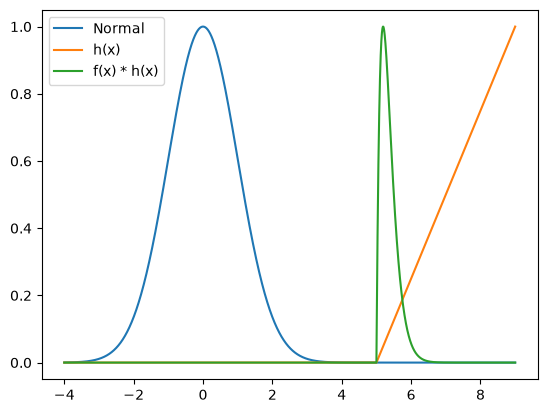

In [81]:
#Gráfico
eixo_x = np.linspace(-4, 9, 10_000)

def f_plot_normal(x, mi):
  return np.exp(-((x-mi)**2)/2)/np.sqrt(2*np.pi)

def h(x):
    return np.maximum(x-5, 0)

plt.plot(eixo_x, f_plot_normal(eixo_x, 0)/np.max(f_plot_normal(eixo_x, 0)), label= "Normal")
plt.plot(eixo_x, h(eixo_x)/np.max(h(eixo_x)), label="h(x)")
plt.plot(eixo_x, h(eixo_x) * f_plot_normal(eixo_x, 0)/np.max(h(eixo_x) * f_plot_normal(eixo_x, 0)), label="f(x) * h(x)")

plt.legend()
plt.show()

In [62]:
dados = normal(0, 1, 200_000)

print(np.mean(np.array(dados) - 5 > 0))

0.0


In [83]:
t = 5

f_t = normal(t, 1, 200_000)

soma = []
for x in f_t:
    if(x-5 > 0):
        soma.append((x-5) * np.exp(-t * x + (t**2)/2))

    else:
        soma.append(0)

print(np.mean(soma))

5.3355895614740304e-08
